In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


df = pd.read_csv("lizard_data.csv")

print("İLK 5 SATIR")
display(df.head())

print("\nSatır Sayısı:", df.shape[0])
print("Sütun Sayısı:", df.shape[1])

print("\nSütunlar")
print(df.columns.tolist())

print("\nYaşam Alanı Dağılımı")
print(df["YasamAlani"].value_counts())

print("\nSayısal Özet")
display(df.describe().round(2))


İLK 5 SATIR


,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac



Satır Sayısı: 320
Sütun Sayısı: 7

Sütunlar
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']

Yaşam Alanı Dağılımı
YasamAlani
Yer     151
Kaya     96
Agac     73
Name: count, dtype: int64

Sayısal Özet


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.00,320.00,320.00,320.00
mean,60.80,145.07,12.50,27.31
std,10.50,26.09,5.66,5.72
min,36.40,76.40,2.57,13.80
25%,52.68,124.45,8.19,22.78
50%,59.75,141.80,10.49,27.15
75%,69.60,166.25,17.40,31.00
max,83.30,209.40,25.93,43.90


 •	Veri setinde toplam kaç gözlem bulunmaktadır?

 Veri seti, farklı yaşam ortamlarında bulunan toplam 320 kedi gözleminden oluşmaktadır.

•	Hangi yaşam ortamında daha fazla, hangisinde daha az kedi gözlemi bulunmaktadır?

 En fazla gözleme sahip yaşam ortamı Yer olarak görülmektedir.
 En az gözleme sahip yaşam ortamı Ağaç'tır.

•	Bu dengesizlik modelimizi nasıl etkileyebilir?

 Sınıf dağılımı dengeli değildir.
 Bu durum modelin Yer sınıfını daha iyi öğrenmesine ve ağaç sınıfını daha az öğrenmesine neden olabilir.

 •	Kedilerin ortalama ağırlığı nedir? Bu değer üç tür için farklı mıdır? Nedenini açıklayın

 Kedilerin ortalama ağırlığı yaklaşık 12.50 gramdır. Evet, üç tür için de birbirinden farklıdır çünkü gövde uzunlukları ve kütleleri birbirinden farklıdır.

  Derinlik      Eğitim MCR        Test MCR
         1           0.488           0.484
         2           0.359           0.312
         3           0.352           0.328
         4           0.324           0.328
         5           0.285           0.438
         6           0.242           0.438
         7           0.156           0.438
         8           0.129           0.469
         9           0.066           0.469
        10           0.051           0.516

Optimum Derinlik = 2


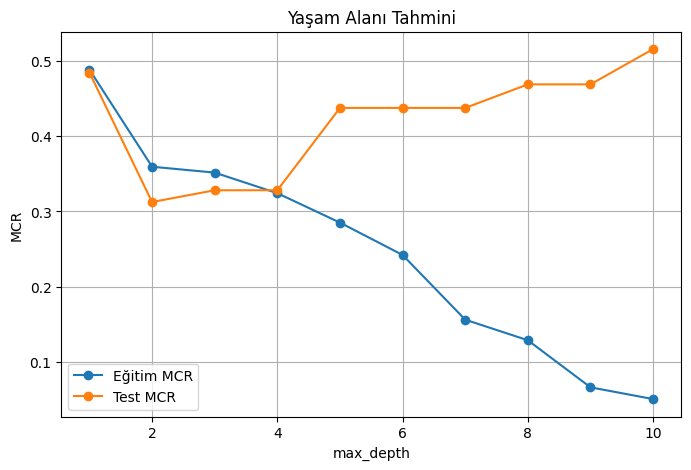

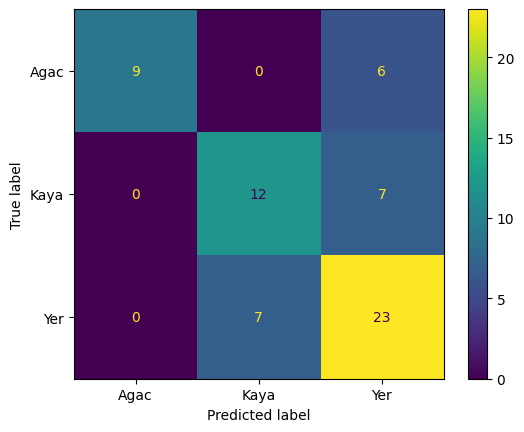

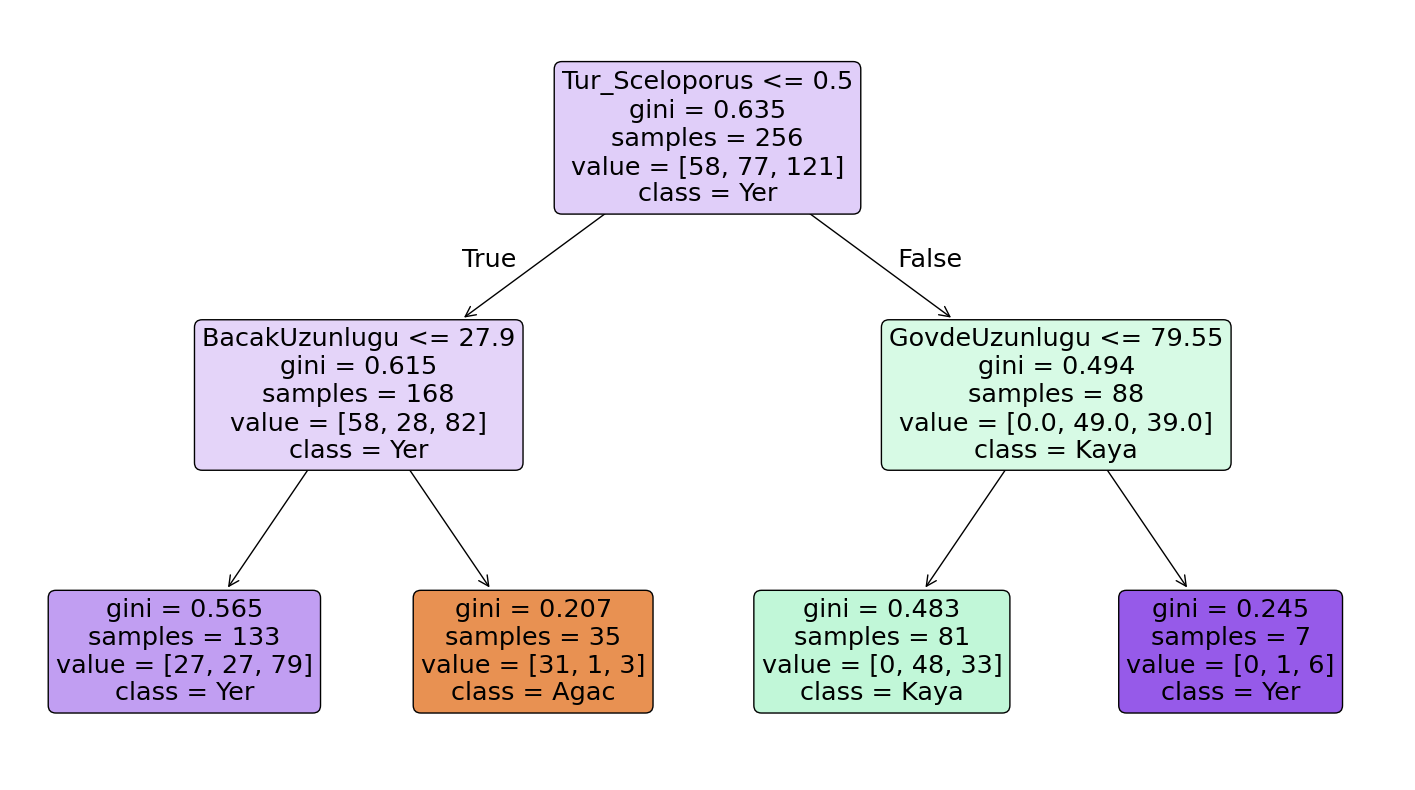

Kök Düğüm: Tur_Sceloporus


In [14]:


hedef = "YasamAlani"

ozellikler = [x for x in df.columns if x != hedef]

X = pd.get_dummies(df[ozellikler])
y = df[hedef]

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

derinlikler = range(1,11)

egitim_mcr = []
test_mcr = []

print(f"{'Derinlik':>10} {'Eğitim MCR':>15} {'Test MCR':>15}")

for derinlik in derinlikler:

    model = DecisionTreeClassifier(
        max_depth=derinlik,
        random_state=42
    )

    model.fit(X_egitim,y_egitim)

    egitim_hata = 1-accuracy_score(
        y_egitim,
        model.predict(X_egitim)
    )

    test_hata = 1-accuracy_score(
        y_test,
        model.predict(X_test)
    )

    egitim_mcr.append(egitim_hata)
    test_mcr.append(test_hata)

    print(f"{derinlik:>10} {egitim_hata:>15.3f} {test_hata:>15.3f}")

en_iyi_derinlik = derinlikler[test_mcr.index(min(test_mcr))]

print("\nOptimum Derinlik =", en_iyi_derinlik)

plt.figure(figsize=(8,5))

plt.plot(
    derinlikler,
    egitim_mcr,
    marker="o",
    label="Eğitim MCR"
)

plt.plot(
    derinlikler,
    test_mcr,
    marker="o",
    label="Test MCR"
)

plt.xlabel("max_depth")
plt.ylabel("MCR")
plt.title("Yaşam Alanı Tahmini")

plt.legend()
plt.grid(True)
plt.show()

final_model = DecisionTreeClassifier(
    max_depth=en_iyi_derinlik,
    random_state=42
)

final_model.fit(X_egitim,y_egitim)

y_tahmin = final_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_tahmin
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot()
plt.show()

plt.figure(figsize=(18,10))

plot_tree(
    final_model,
    feature_names=X.columns,
    class_names=final_model.classes_,
    filled=True,
    rounded=True
)

plt.show()

kok = X.columns[
    final_model.tree_.feature[0]
]

print("Kök Düğüm:", kok)

•	Veri bölme işleminde stratify parametresi kullanılmazsa ne olur? Deneyin ve farkı açıklayın.

 stratify=y kaldırılırsa sınıf oranları korunmaz.
 Bazı sınıflar eğitim veya test kümesinde az temsil edilebilir.

•	random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi? Deneyin ve nedenini açıklayın.

 random_state değeri değişirse eğitim ve test kümelerine düşen gözlemler değişir.
 Bu nedenle doğruluk ve MCR değerleri de değişebilir.

  Derinlik      Eğitim MCR        Test MCR
         1           0.266           0.281
         2           0.184           0.203
         3           0.184           0.203
         4           0.137           0.297
         5           0.105           0.234
         6           0.074           0.250
         7           0.027           0.219
         8           0.008           0.281
         9           0.000           0.281
        10           0.000           0.281

Optimum Derinlik = 2


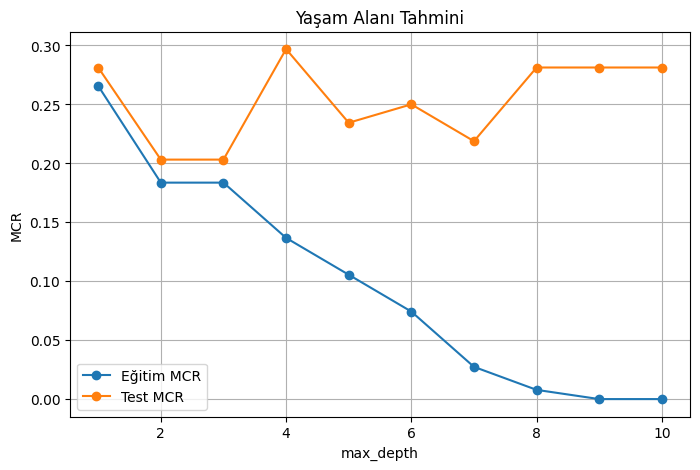

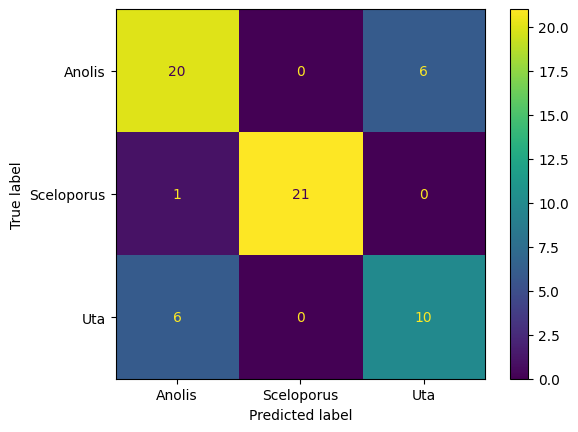

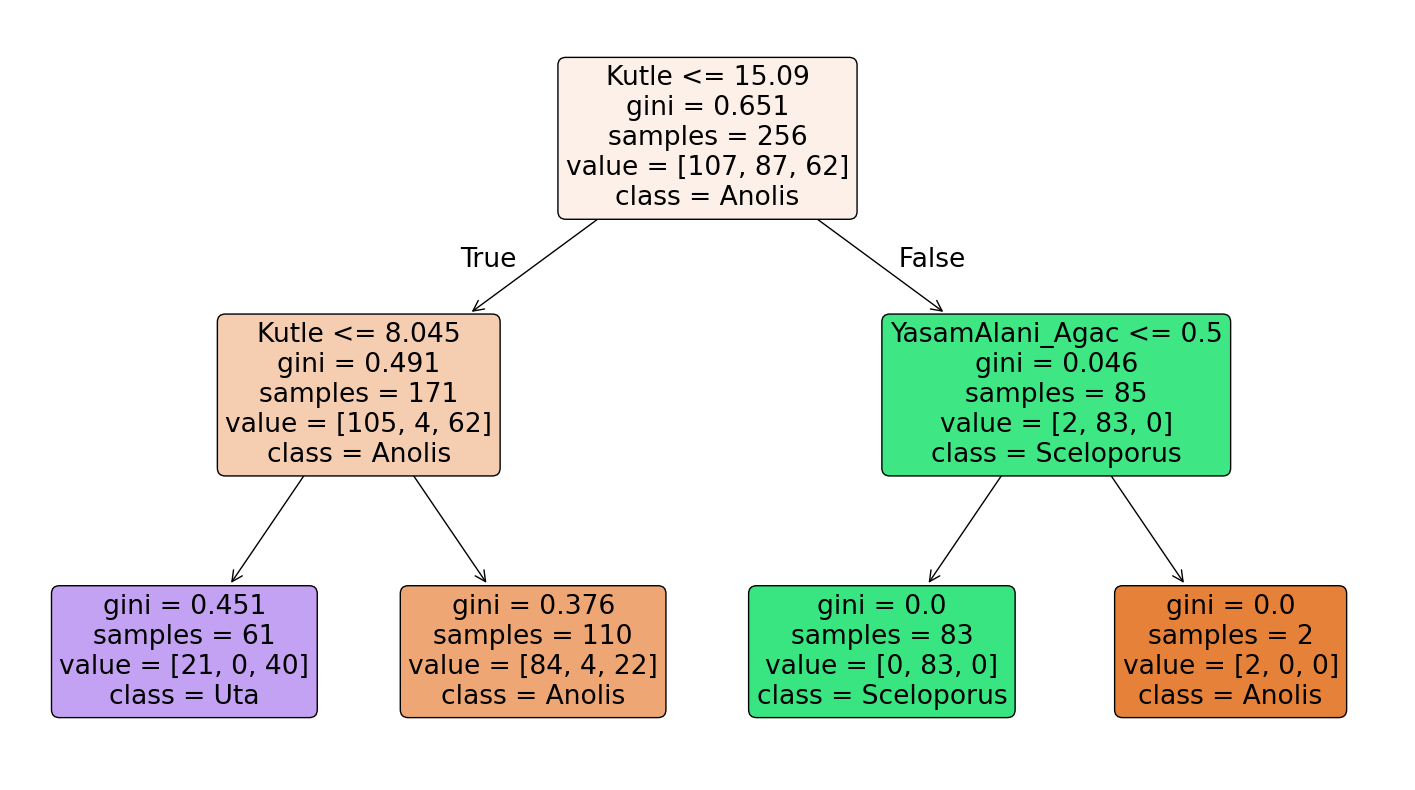

Kök Düğüm: Kutle


In [15]:


hedef = "Tur"

ozellikler = [x for x in df.columns if x != hedef]

X = pd.get_dummies(df[ozellikler])
y = df[hedef]

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

derinlikler = range(1,11)

egitim_mcr = []
test_mcr = []

print(f"{'Derinlik':>10} {'Eğitim MCR':>15} {'Test MCR':>15}")

for derinlik in derinlikler:

    model = DecisionTreeClassifier(
        max_depth=derinlik,
        random_state=42
    )

    model.fit(X_egitim,y_egitim)

    egitim_hata = 1-accuracy_score(
        y_egitim,
        model.predict(X_egitim)
    )

    test_hata = 1-accuracy_score(
        y_test,
        model.predict(X_test)
    )

    egitim_mcr.append(egitim_hata)
    test_mcr.append(test_hata)

    print(f"{derinlik:>10} {egitim_hata:>15.3f} {test_hata:>15.3f}")

en_iyi_derinlik = derinlikler[test_mcr.index(min(test_mcr))]

print("\nOptimum Derinlik =", en_iyi_derinlik)

plt.figure(figsize=(8,5))

plt.plot(
    derinlikler,
    egitim_mcr,
    marker="o",
    label="Eğitim MCR"
)

plt.plot(
    derinlikler,
    test_mcr,
    marker="o",
    label="Test MCR"
)

plt.xlabel("max_depth")
plt.ylabel("MCR")
plt.title("Yaşam Alanı Tahmini")

plt.legend()
plt.grid(True)
plt.show()

final_model = DecisionTreeClassifier(
    max_depth=en_iyi_derinlik,
    random_state=42
)

final_model.fit(X_egitim,y_egitim)

y_tahmin = final_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_tahmin
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot()
plt.show()

plt.figure(figsize=(18,10))

plot_tree(
    final_model,
    feature_names=X.columns,
    class_names=final_model.classes_,
    filled=True,
    rounded=True
)

plt.show()

kok = X.columns[
    final_model.tree_.feature[0]
]

print("Kök Düğüm:", kok)

•	Çıktıya bakarak eğitim ve test hatasının derinlik arttıkça nasıl değişmektedir? Eğitim ve test değerlerine bakarak gerekçenizi yazın.

 Karar ağacının derinliği arttıkça model, kedi verileri üzerindeki örüntüleri daha iyi öğrenmektedir; ancak bu durum aşırı öğrenme riskini de beraberinde getirebilir.
 Bir noktadan sonra test hatası tekrar yükselmektedir.
 Bu durum overfitting yani aşırı öğrenme olduğunu göstermektedir.

•	Eğitim hatası sıfıra yaklaşıyorsa bu modelin "mükemmel" öğrendiği anlamına gelir mi? Sizce ne anlama geliyor?

 Eğitim hatasının sıfıra yaklaşması modelin eğitim verisini ezberlediğini gösterebilir.

•	Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.

Eğitim hatası düşmeye devam ederken test hatasının artmaya başladığı ilk nokta 5. derinliktir (max_depth = 5). Derinlik 4'ten 5'e çıkarıldığında eğitim MCR değeri 0.324'ten 0.285'e düşmüş, yani model eğitim verisini daha iyi öğrenmiştir. Ancak aynı anda test MCR değeri 0.328'den 0.438'e yükselmiştir, yani model yeni veriler üzerinde daha kötü performans göstermeye başlamıştır.

Bu noktada modelde aşırı öğrenme (overfitting) meydana gelmiştir. Model eğitim verisindeki genel örüntüleri öğrenmek yerine veriye özgü ayrıntıları ve gürültüyü de ezberlemeye başlamıştır. Bu nedenle eğitim verisinde başarılı görünmesine rağmen daha önce görmediği test verilerinde hata oranı artmıştır. Bu durum, ağacın gereğinden fazla karmaşık hale geldiğini ve genelleme yeteneğinin azaldığını göstermektedir.

•	Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.

Yalnızca eğitim ve test hatalarına bakacak olsaydım, **2. derinliği (max_depth = 2)** seçerdim. Çünkü bu derinlikte test hatası yaklaşık **0.3125** ile en düşük değerlerden birini vermektedir. Ayrıca model çok karmaşık olmadığı için veriyi ezberleme riski de düşüktür.

Daha yüksek derinliklerde eğitim hatası azalmaya devam etse de test hatasının arttığı görülmektedir. Bu durum modelin eğitim verisine aşırı uyum sağladığını ve yeni veriler üzerinde daha kötü performans göstermeye başladığını göstermektedir. Bu nedenle yalnızca eğitim başarısına bakmak doğru değildir. Hem eğitim hem de test hataları birlikte değerlendirildiğinde, 2. derinlik modelin doğruluk ve genelleme performansı arasında en uygun dengeyi sağlamaktadır.

•	En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?

Evet, en düşük test hatası ile en düşük eğitim hatası farklı derinliklerde ortaya çıkmıştır. Eğitim hatası en düşük değerine ağacın daha derin olduğu seviyelerde ulaşırken, test hatası daha düşük derinliklerde en iyi sonucu vermiştir.

 Bu durum, eğitim verisinde çok başarılı olan bir modelin her zaman yeni veriler üzerinde de en iyi performansı göstermediğini göstermektedir. Ağacın derinliği arttıkça model eğitim verisini daha iyi öğrenmekte, hatta bazı durumlarda ezberlemektedir. Ancak bu durum test verisindeki başarının düşmesine neden olabilmektedir. Bu nedenle model seçiminde yalnızca eğitim hatasına bakmak yeterli değildir. Test hatasının da dikkate alınması gerekir. Bu sonuç, karar ağacında aşırı öğrenme (overfitting) probleminin oluşabileceğini ve optimum derinliğin eğitim performansına göre değil, test performansına göre belirlenmesi gerektiğini göstermektedir.


  Derinlik      Eğitim MCR        Test MCR
         1           0.352           0.438
         2           0.344           0.438
         3           0.223           0.328
         4           0.215           0.328
         5           0.156           0.312
         6           0.152           0.312
         7           0.098           0.391
         8           0.062           0.328
         9           0.023           0.297
        10           0.012           0.391

Optimum Derinlik = 9


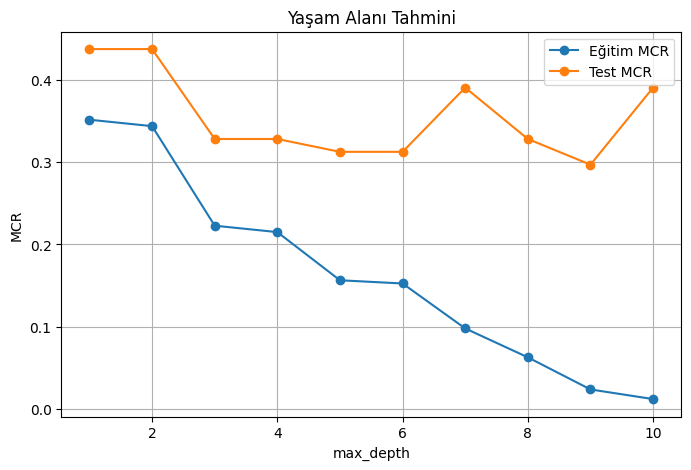

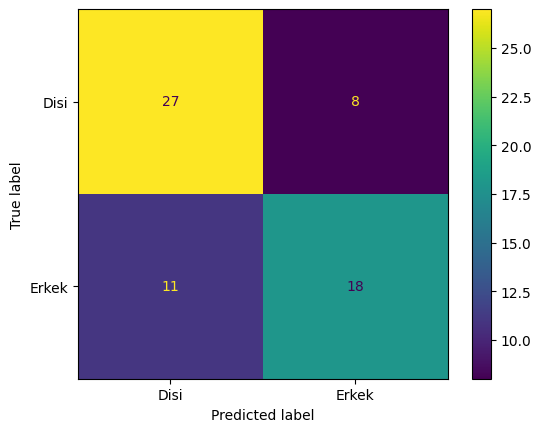

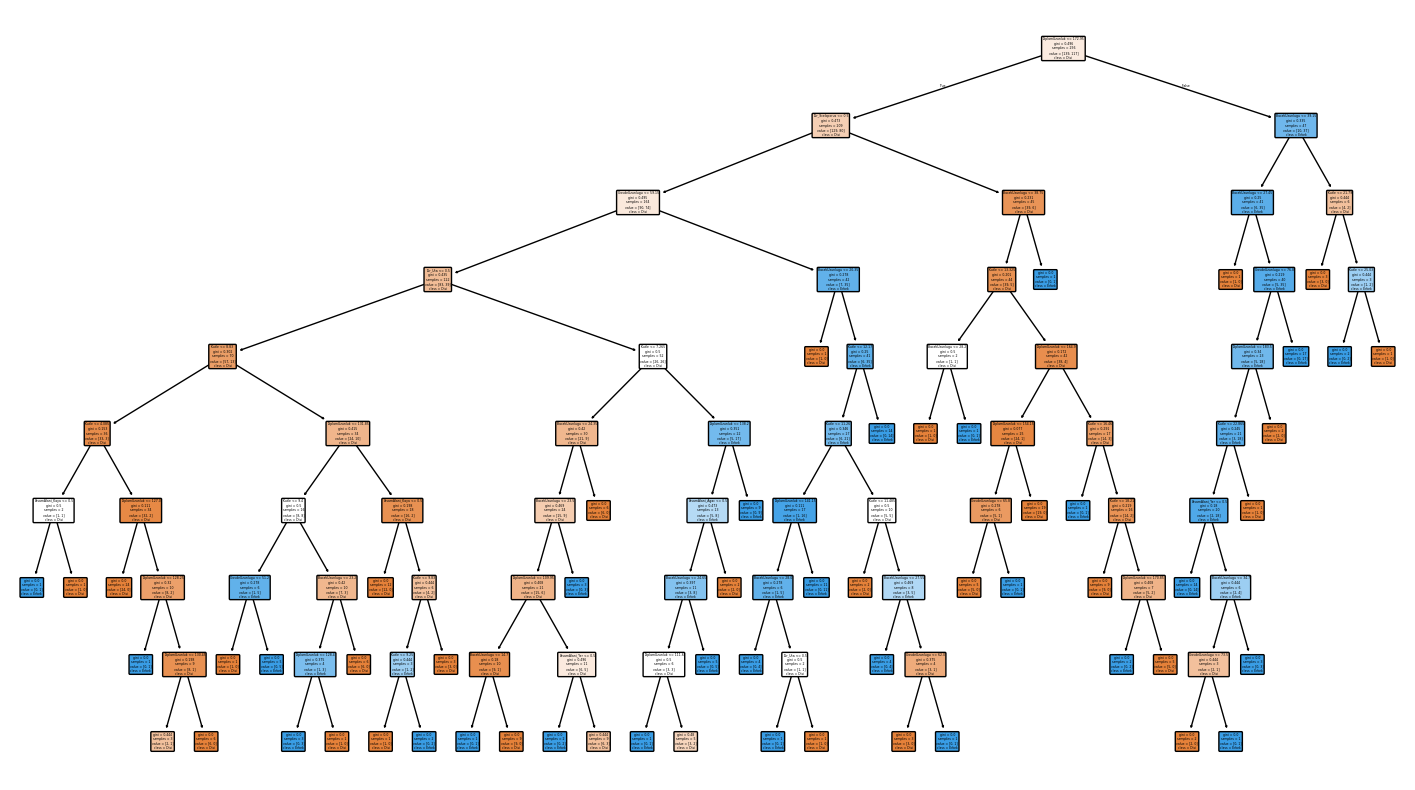

Kök Düğüm: ToplamUzunluk


In [16]:


hedef = "Cinsiyet"

ozellikler = [x for x in df.columns if x != hedef]

X = pd.get_dummies(df[ozellikler])
y = df[hedef]

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

derinlikler = range(1,11)

egitim_mcr = []
test_mcr = []

print(f"{'Derinlik':>10} {'Eğitim MCR':>15} {'Test MCR':>15}")

for derinlik in derinlikler:

    model = DecisionTreeClassifier(
        max_depth=derinlik,
        random_state=42
    )

    model.fit(X_egitim,y_egitim)

    egitim_hata = 1-accuracy_score(
        y_egitim,
        model.predict(X_egitim)
    )

    test_hata = 1-accuracy_score(
        y_test,
        model.predict(X_test)
    )

    egitim_mcr.append(egitim_hata)
    test_mcr.append(test_hata)

    print(f"{derinlik:>10} {egitim_hata:>15.3f} {test_hata:>15.3f}")

en_iyi_derinlik = derinlikler[test_mcr.index(min(test_mcr))]

print("\nOptimum Derinlik =", en_iyi_derinlik)

plt.figure(figsize=(8,5))

plt.plot(
    derinlikler,
    egitim_mcr,
    marker="o",
    label="Eğitim MCR"
)

plt.plot(
    derinlikler,
    test_mcr,
    marker="o",
    label="Test MCR"
)

plt.xlabel("max_depth")
plt.ylabel("MCR")
plt.title("Yaşam Alanı Tahmini")

plt.legend()
plt.grid(True)
plt.show()

final_model = DecisionTreeClassifier(
    max_depth=en_iyi_derinlik,
    random_state=42
)

final_model.fit(X_egitim,y_egitim)

y_tahmin = final_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_tahmin
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot()
plt.show()

plt.figure(figsize=(18,10))

plot_tree(
    final_model,
    feature_names=X.columns,
    class_names=final_model.classes_,
    filled=True,
    rounded=True
)

plt.show()

kok = X.columns[
    final_model.tree_.feature[0]
]

print("Kök Düğüm:", kok)

•	Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?

 Yaklaşık 5. derinlik seviyesinden sonra eğitim ve test performansları arasındaki fark belirginleşmektedir. Bu durum modelin genelleme yeteneğini sorgulatmaktadır. Bu durum modelin aşırı öğrenmeye (overfitting) başladığını ve yeni verilerdeki başarısının düşebileceğini göstermektedir.

 •	Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?

 Eğitim ve test eğrileri arasındaki mesafe derinlik arttıkça açılıyorsa buna aşırı öğrenme (overfitting) denir. Model eğitim verisini ezberlemeye başlar ve test verisinde daha fazla hata yapar.

• Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?

 Grafiğe bakarak max_depth = 2 değerini seçerdim. Çünkü bu noktada test hatası en düşük seviyededir ve eğitim ile test eğrileri birbirine oldukça yakındır. Sayısal tablodaki kararım da aynı olurdu. Bu derinlik, modelin hem iyi öğrenmesini hem de yeni veriler üzerinde başarılı olmasını sağlamaktadır.

 •	Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?

  Hayır, optimum derinlik her hedef değişken için aynı çıkmamıştır.

 Yaşam Alanı: max_depth = 2
 Tür: max_depth = 2
 Cinsiyet: max_depth = 9

Bu farklılığın nedeni, her hedef değişkenin veri içindeki yapısının farklı olmasıdır. Yaşam ortamı ve tür değişkenleri daha az sayıda kural ile açıklanabilirken, cinsiyeti doğru tahmin edebilmek için daha fazla ayrıntıya ihtiyaç duyulmuştur. Bu nedenle cinsiyet modeli daha derin bir ağaçla en iyi sonucu vermiştir.

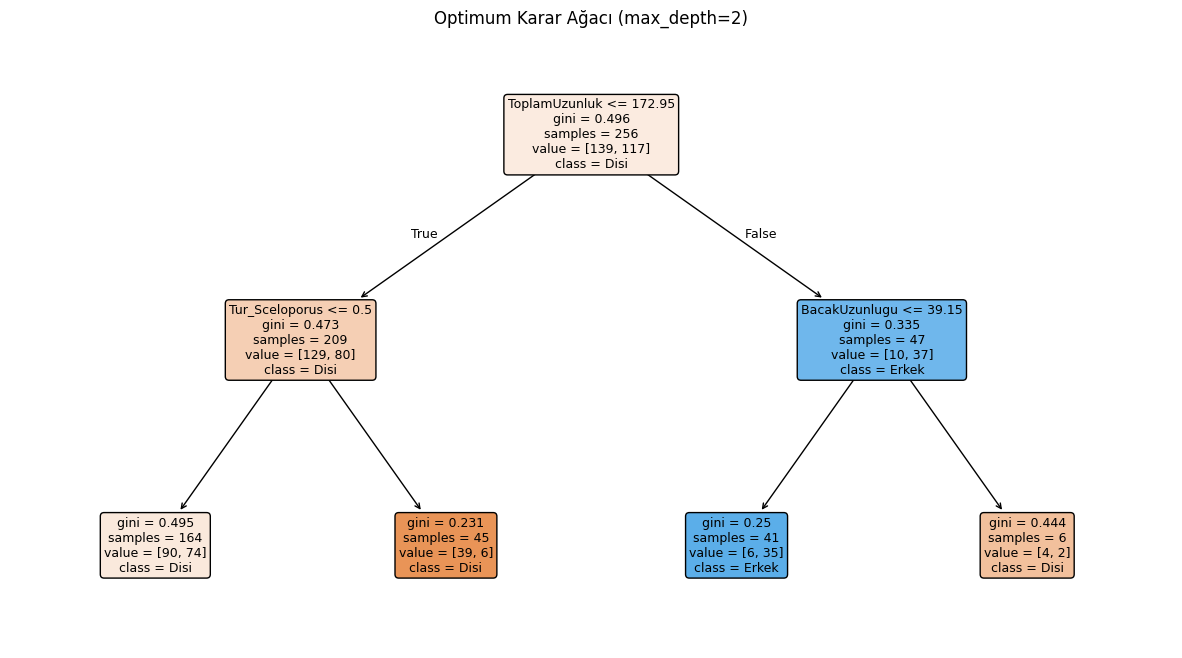

In [19]:
# Optimum Model

optimum_agac = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

optimum_agac.fit(X_egitim,y_egitim)


plt.figure(figsize=(15,8))

plot_tree(
    optimum_agac,
    feature_names=X.columns,
    class_names=optimum_agac.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Optimum Karar Ağacı (max_depth=2)")
plt.show()





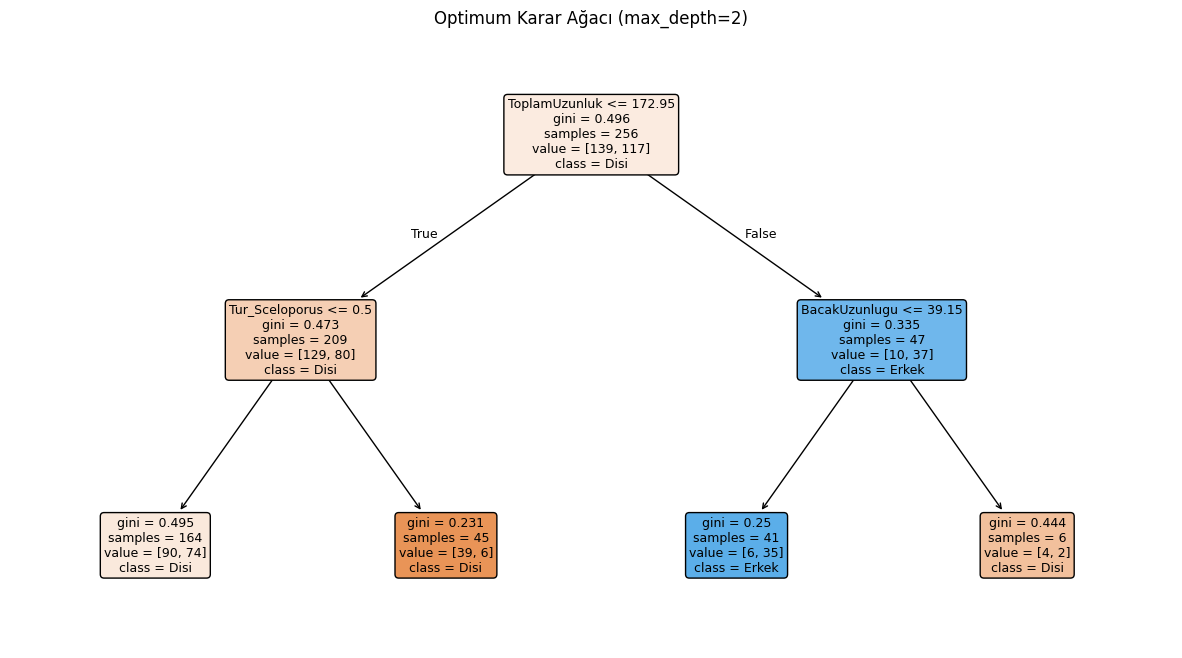

In [20]:
optimum_agac = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

optimum_agac.fit(X_egitim,y_egitim)


plt.figure(figsize=(15,8))

plot_tree(
    optimum_agac,
    feature_names=X.columns,
    class_names=optimum_agac.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Optimum Karar Ağacı (max_depth=2)")
plt.show()

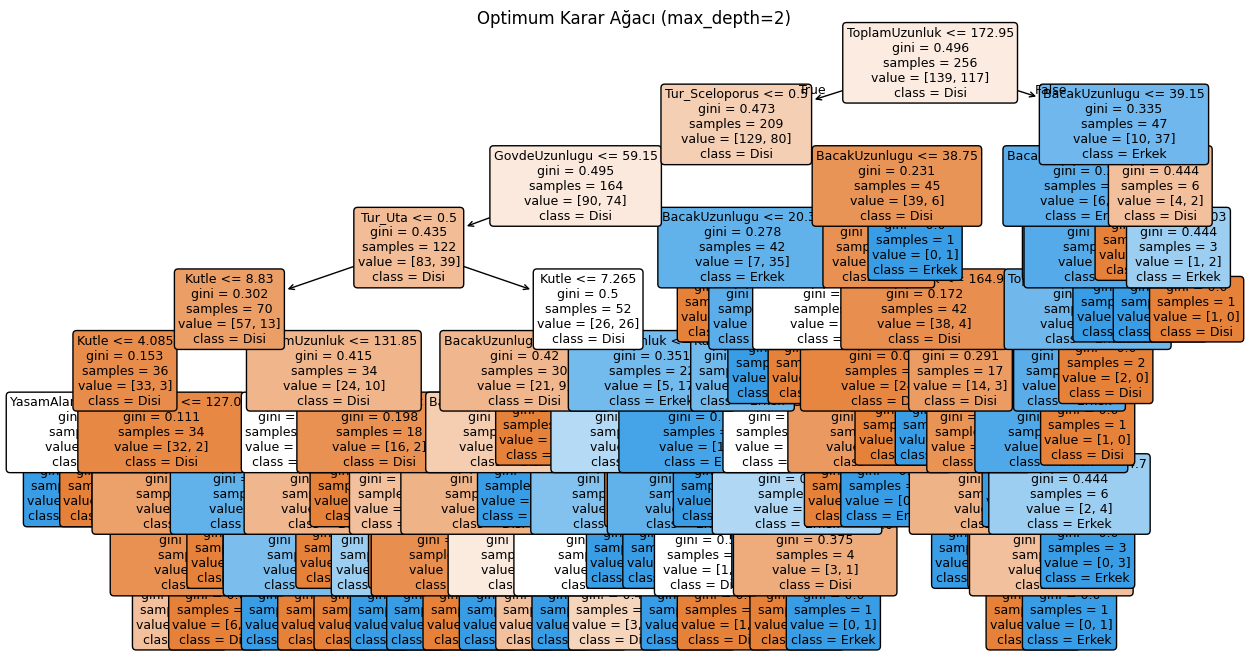

In [21]:
optimum_agac = DecisionTreeClassifier(
    max_depth=9,
    random_state=42
)

optimum_agac.fit(X_egitim,y_egitim)


plt.figure(figsize=(15,8))

plot_tree(
    optimum_agac,
    feature_names=X.columns,
    class_names=optimum_agac.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Optimum Karar Ağacı (max_depth=2)")
plt.show()

•	Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?

Yaşam Alanı Tahmini

Kök düğüm: Tur_Sceloporus

Bu değişken yaşam alanlarını ayırmada en fazla bilgi sağladığı için ilk sırada seçilmiştir.

Tür Tahmini

Kök düğüm: Kutle

Kütle, türler arasındaki farkları en iyi gösteren değişken olduğu için kök düğümde yer almıştır.

Cinsiyet Tahmini

Kök düğüm: ToplamUzunluk

Toplam uzunluk, cinsiyetleri ayırt etmede en etkili değişken olduğu için ilk sırada kullanılmıştır.

•	Ağaç yapraktan köke doğru okunduğunda bir kediyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

 Optimum ağaçta bir kediyi sınıflandırmak için genellikle 2-3 karar yeterli olmaktadır. Bu durum, veri setindeki sınıfların çok karmaşık olmadığını ve birkaç temel özellik kullanılarak başarılı şekilde ayırt edilebildiğini göstermektedir.

•	Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?

 Evet, hedef değişken değiştirildiğinde kök düğüm de değişmiştir. Yaşam Alanı modelinde kök düğüm Tur_Sceloporus, Tür modelinde Kutle, Cinsiyet modelinde ise ToplamUzunluk olmuştur. Bu durum, her hedef değişkeni tahmin etmek için en önemli özelliğin farklı olduğunu göstermektedir. Model, her hedef için en fazla bilgi sağlayan değişkeni kök düğüm olarak seçmektedir.

•	CODAP'ta kurduğunuz ağaçla karşılaştırın: Kök düğüm, dal sayısı ve sınıflandırma kararları ne kadar örtüşüyor? Farklılık varsa nereden kaynaklanıyor olabilir?

 CODAP'ta oluşturduğum ağaç ile Python'da oluşturduğum ağaç büyük ölçüde örtüşmektedir. Kök düğüm ve temel sınıflandırma kararları benzerdir. Küçük farklılıklar ise kullanılan algoritma ayarları, veri bölme yöntemi ve optimum derinlik seçiminden kaynaklanmış olabilir.

●	Her ortam size farklı bir şey kattı mı? Her bir ortamın neler kattığını yazın.

 Evet, kullanılan her araç hem akademik hem de uygulamalı öğrenme sürecime farklı açılardan katkı sağlamıştır. Data kartları karar ağacının mantığını anlamama yardımcı oldu. CODAP, ağacın görsel olarak nasıl oluştuğunu daha iyi görmemi sağladı. Python ise modeli kodlayarak performansını ölçmeyi, farklı derinlikleri karşılaştırmayı ve sonuçları analiz etmeyi öğretti.

●	Hangi ortamda "modelim ne yapıyor" sorusunu daha iyi anladınız? Nedeninizi açıklayın

 Modelin ne yaptığını en iyi CODAP ortamında anladım. Çünkü karar ağacının nasıl oluştuğunu ve her bölünmenin nasıl yapıldığını görsel olarak takip etmek daha kolaydı. Bu sayede modelin karar verme sürecini daha iyi kavradım.

●	Hangi ortam size daha kolay geldi? Bu kolaylık gerçekten anladığınızı mı, yoksa sadece alıştığınızı mı gösteriyor? Nedeninizi açıklayın.

 Bana en kolay gelen ortam CODAP oldu. Görsel olduğu için karar ağacını takip etmek daha kolaydı. Bu kolaylığın hem konuyu anlamamdan hem de CODAP'a alışmış olmamdan kaynaklandığını düşünüyorum.

●	Hangi ortamda en çok zorlandınız ve bu zorluk neden kaynaklanıyordu? Aracın kendisi mi, yoksa karar ağacı kavramının o ortamda daha mı görünmez olması mıydı? Nedeninizi açıklayın.

 En çok Python ortamında zorlandım. Bunun nedeni karar ağacı mantığından çok kod yazma ve hata düzeltme süreciydi. Kod doğru çalıştığında modeli anlamak kolaylaştı, ancak başlangıçta teknik kısımlar daha fazla zorladı.

●	Yaptığınız bir hatayı hangi ortamda daha kolay fark ettiniz? Sizi uyaran şey aracın kendisi miydi, yoksa başka bir şey mi?

 Yaptığım hataları en kolay Python ortamında fark ettim. Çünkü hata mesajları yanlış yaptığım kısmı gösteriyordu. Böylece hatayı bulup düzeltmem daha kolay oldu.

●	Bir ortamda rahatlıkla yapabildiğiniz ama bir diğerinde hiç yapamadığınız bir şey oldu mu?

 Evet. Python ortamında farklı derinlikleri deneyip modelin başarısını grafiklerle karşılaştırabildim. Bunu data kartlarıyla veya CODAP'ta aynı ayrıntıda yapmak mümkün değildi.

●	Üç ortamdan birinin diğerinin yerini tutamayacağı bir durum var mı? Nedeninizi açıklayın.

 Evet. Üç ortamın da farklı avantajları vardı. Data kartları mantığı anlamamı, CODAP görselleştirmeyi, Python ise modeli analiz etmeyi sağladı. Bu nedenle hiçbirinin tek başına diğerinin yerini tamamen tutamayacağını düşünüyorum.

Soru 2 — Veri Anlayışı

●	Modelinizin kök düğümde seçtiği değişken sizi şaşırttı mı? Biyolojik açıdan bu seçim mantıklı mı?

 Hayır, şaşırtmadı. Modelin kök düğümde **Tur_Sceloporus** değişkenini seçmesi biyolojik açıdan mantıklıdır. Çünkü bazı kedi türleri belirli yaşam alanlarında daha sık görülmektedir ve bu değişken yaşam ortamını ayırt etmede önemli bilgi sağlamaktadır.

●	Ağaçta yaşayan bir kedinin yerde yaşayandan fiziksel olarak farklı olmasını bekler miydiniz? Modeliniz bu farkı yakalayabildi mi?

 Evet, beklerdim. Ağaçta yaşayan kedilerin yaşam ortamına uyum sağlamak için fiziksel özelliklerinin farklı olması normaldir. Model de bu farklılıkları büyük ölçüde yakalayarak yaşam ortamını tahmin edebilmiştir.

●	Modelinizin yanlış sınıflandırdığı bireyler hangi yaşam ortamına aitti? Bunun biyolojik bir açıklaması olabilir mi?

Yanlış sınıflandırılan bireyler daha çok Ağaç ve Kaya yaşam alanlarına aittir. Çünkü bu sınıflardaki birey sayısı Yer sınıfına göre daha azdır.

Biyolojik olarak da bu durum mantıklıdır. Bazı kedilerin fiziksel özellikleri birbirine benzediği için model, özellikle Kaya ve Ağaç yaşam alanlarını ayırmakta zorlanmış olabilir.

●	Veriyi ilk gördüğünüzde kendiniz hangi değişkenin en belirleyici olacağını tahmin etmiştiniz? Modelinizin bulgusuyla örtüştü mü?

 Veriyi ilk gördüğümde **Kütle** değişkeninin en belirleyici olacağını düşünmüştüm. Model ise **Tur_Sceloporus** değişkenini kök düğüm olarak seçti. Bu nedenle tahminim modelin bulgusuyla tam olarak örtüşmedi.

Soru 3 — Model Performansı

● Hangi sınıf en iyi, hangisi en kötü tahmin edildi? Bunun bir açıklaması var mı?

 Optimum derinlikte elde ettiğim **MCR değeri yaklaşık 0.3125** oldu. Model en iyi **Yer** sınıfını tahmin etti. En fazla hata ise **Ağaç** sınıfında görüldü. Bunun nedeni, Ağaç sınıfındaki örnek sayısının daha az olması ve fiziksel özelliklerinin diğer yaşam alanlarıyla benzerlik göstermesidir.

●	MCR değeriniz sizi tatmin etti mi? "İyi" bir model için bu değerin ne olması gerektiğini düşünüyorsunuz?

 MCR değerim beni genel olarak tatmin etti. **0.3125** değeri modelin çoğu tahmini doğru yaptığını göstermektedir. Bence iyi bir modelde MCR değerinin mümkün olduğunca **0'a yakın** olması beklenir. Bu, modelin daha az hata yaptığını gösterir.

●	Aynı veriyle farklı bir hedef değişken seçseydiniz (Tur ya da Cinsiyet) MCR değeri değişir miydi? Değiştiyse neden?

 Evet, değişirdi. Çünkü her hedef değişkenin tahmin edilme zorluğu farklıdır. Nitekim bu çalışmada **Tür** ve **Cinsiyet** için elde edilen MCR değerleri de yaşam ortamından farklı çıkmıştır. Bu durum, değişkenlerin veriyle olan ilişkisinin farklı olmasından kaynaklanmaktadır.

●	Modelin başarısız olduğu durumlar size veri hakkında ne söylüyor?

 Modelin başarısız olduğu durumlar, bazı yaşam alanlarının fiziksel özelliklerinin birbirine benzediğini göstermektedir. Bu nedenle model bazı bireyleri doğru sınıflandırmakta zorlanmıştır.

Soru 4 — Karar Ağaçlarının Sınırları

● Modelinizin hata yaptığı durumlar rastgele mi görünüyor, yoksa belirli bir örüntü var mı?

 Modelin yaptığı hatalar tamamen rastgele görünmüyor. Hatalar daha çok fiziksel özellikleri birbirine benzeyen kedilerde ortaya çıkmıştır.

●	Bu modelin daha iyi sonuç verebilmesi için neler yapılabilir? Yalnızca teknik değil, verinin kendisiyle ilgili ne değişebilir?

 Modelin daha iyi sonuç vermesi için veri sayısı artırılabilir ve daha fazla fiziksel özellik eklenebilir. Ayrıca sınıflar arasındaki veri dengesinin sağlanması modelin doğruluğunu artırabilir.

●	Karar ağacı yerine farklı bir model kullansaydınız sonuç değişir miydi? Neden?

 Evet, değişebilirdi. Çünkü farklı makine öğrenmesi modelleri veriyi farklı şekillerde öğrenir. Bazı modeller bu veri üzerinde karar ağacına göre daha yüksek doğruluk sağlayabilir.

●	Bu deneyimden sonra bir arkadaşınıza "karar ağacı nedir, ne işe yarar, nerede yetersiz kalır?" diye sorsalar ne söylerdiniz?

 Karar ağacı, verileri belirli kurallara göre sınıflandıran bir makine öğrenmesi yöntemidir. Verileri anlamayı ve tahmin yapmayı kolaylaştırır. Ancak veri çok karmaşık olduğunda veya benzer özellikler bulunduğunda hata yapabilir.









## Colab'e Dosya Yükleme Yöntemleri

Verilerinizi Colab ortamına yüklemek için birkaç yaygın yöntem bulunmaktadır:

1.  **Yerel Makinenizden Yükleme:**
    *   Sol taraftaki dosya simgesine tıklayarak 'Dosyalar' panelini açın.
    *   `lizard_data.csv` gibi yerel dosyanızı yüklemek için 'Yükle' simgesini (yukarıyı gösteren ok) tıklayın. Bu, dosyayı oturum süresi boyunca `/content/` dizinine yükler. Oturum sona erdiğinde dosya silinir.
    *   Alternatif olarak, aşağıdaki Python kodunu kullanabilirsiniz:

    ```python
    from google.colab import files
    uploaded = files.upload()

    for fn in uploaded.keys():
      print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
    ```

2.  **Google Drive'dan Bağlama:**
    *   Colab not defterinizi Google Drive'ınıza bağlayarak Drive'da depolanan dosyalara doğrudan erişebilirsiniz. Bu yöntem, oturumlar arasında verilerinizin kalıcı olmasını sağlar.
    *   Aşağıdaki kodu kullanın ve talimatları takip edin:

    ```python
    from google.colab import drive
    drive.mount('/content/drive')
    ```
    *   Drive'ınız bağlandıktan sonra, dosyanıza erişim yolu `/content/drive/My Drive/your_folder/lizard_data.csv` gibi olacaktır.

3.  **GitHub veya Başka Bir URL'den İndirme:**
    *   Dosyanız halka açık bir URL'de (örneğin GitHub'da) barındırılıyorsa, `wget` veya `!curl` gibi shell komutlarını kullanarak indirebilirsiniz:

    ```python
    !wget -q https://example.com/lizard_data.csv
    # veya
    !curl -O https://example.com/lizard_data.csv
    ```

Lütfen `lizard_data.csv` dosyanızı bu yöntemlerden birini kullanarak yüklediğinizden veya doğru yolu sağladığınızdan emin olun.

In [13]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
  print(f'Yüklenen dosya: {filename}')

KeyboardInterrupt: 